# Ilm Academy — Day 1 Analytics EDA
**Scenario:** Ilm Academy (8,000 online students) currently gives every student the same linear path, and ~45% drop out before Week 4.

This notebook analyzes:
1. **Accuracy per Concept** (45 Python concepts)
2. **Learning Curves** (accuracy across attempts by ability cohort)
3. **Dropout Points** (weekly attrition & pre-Week-4 bottleneck concepts)
4. **Hardest Concepts** (lowest accuracy & highest response-time concepts)


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
BASE_DIR = Path('..').resolve()
DATA_DIR = BASE_DIR / 'data'
OUT_DIR = BASE_DIR / 'outputs'
OUT_DIR.mkdir(exist_ok=True)

profiles = pd.read_csv(DATA_DIR / 'student_profiles.csv')
interactions = pd.read_csv(DATA_DIR / 'learner_interactions.csv')
graph_meta = json.loads((DATA_DIR / 'concept_graph.json').read_text(encoding='utf-8'))
qbank = json.loads((DATA_DIR / 'question_bank.json').read_text(encoding='utf-8'))

print(f'Students: {len(profiles):,} | Interactions: {len(interactions):,} | '
      f'Concepts: {graph_meta["num_concepts"]} (DAG={graph_meta["is_dag"]}) | Questions: {len(qbank)}')
pre_w4 = ((profiles['dropped_out'] == 1) & (profiles['dropout_week'] < 4)).mean()
print(f'Overall Accuracy: {interactions["correct"].mean():.1%} | Pre-Week-4 Dropout: {pre_w4:.1%}')


Students: 1,000 | Interactions: 81,974 | Concepts: 45 (DAG=True) | Questions: 225
Overall Accuracy: 55.0% | Pre-Week-4 Dropout: 40.4%


## 1. Accuracy per Concept


INSIGHT: Concept accuracy spans 24.1% (time_complexity) to 71.9% (if_elif_else), with steep drops on later/bottleneck topics.


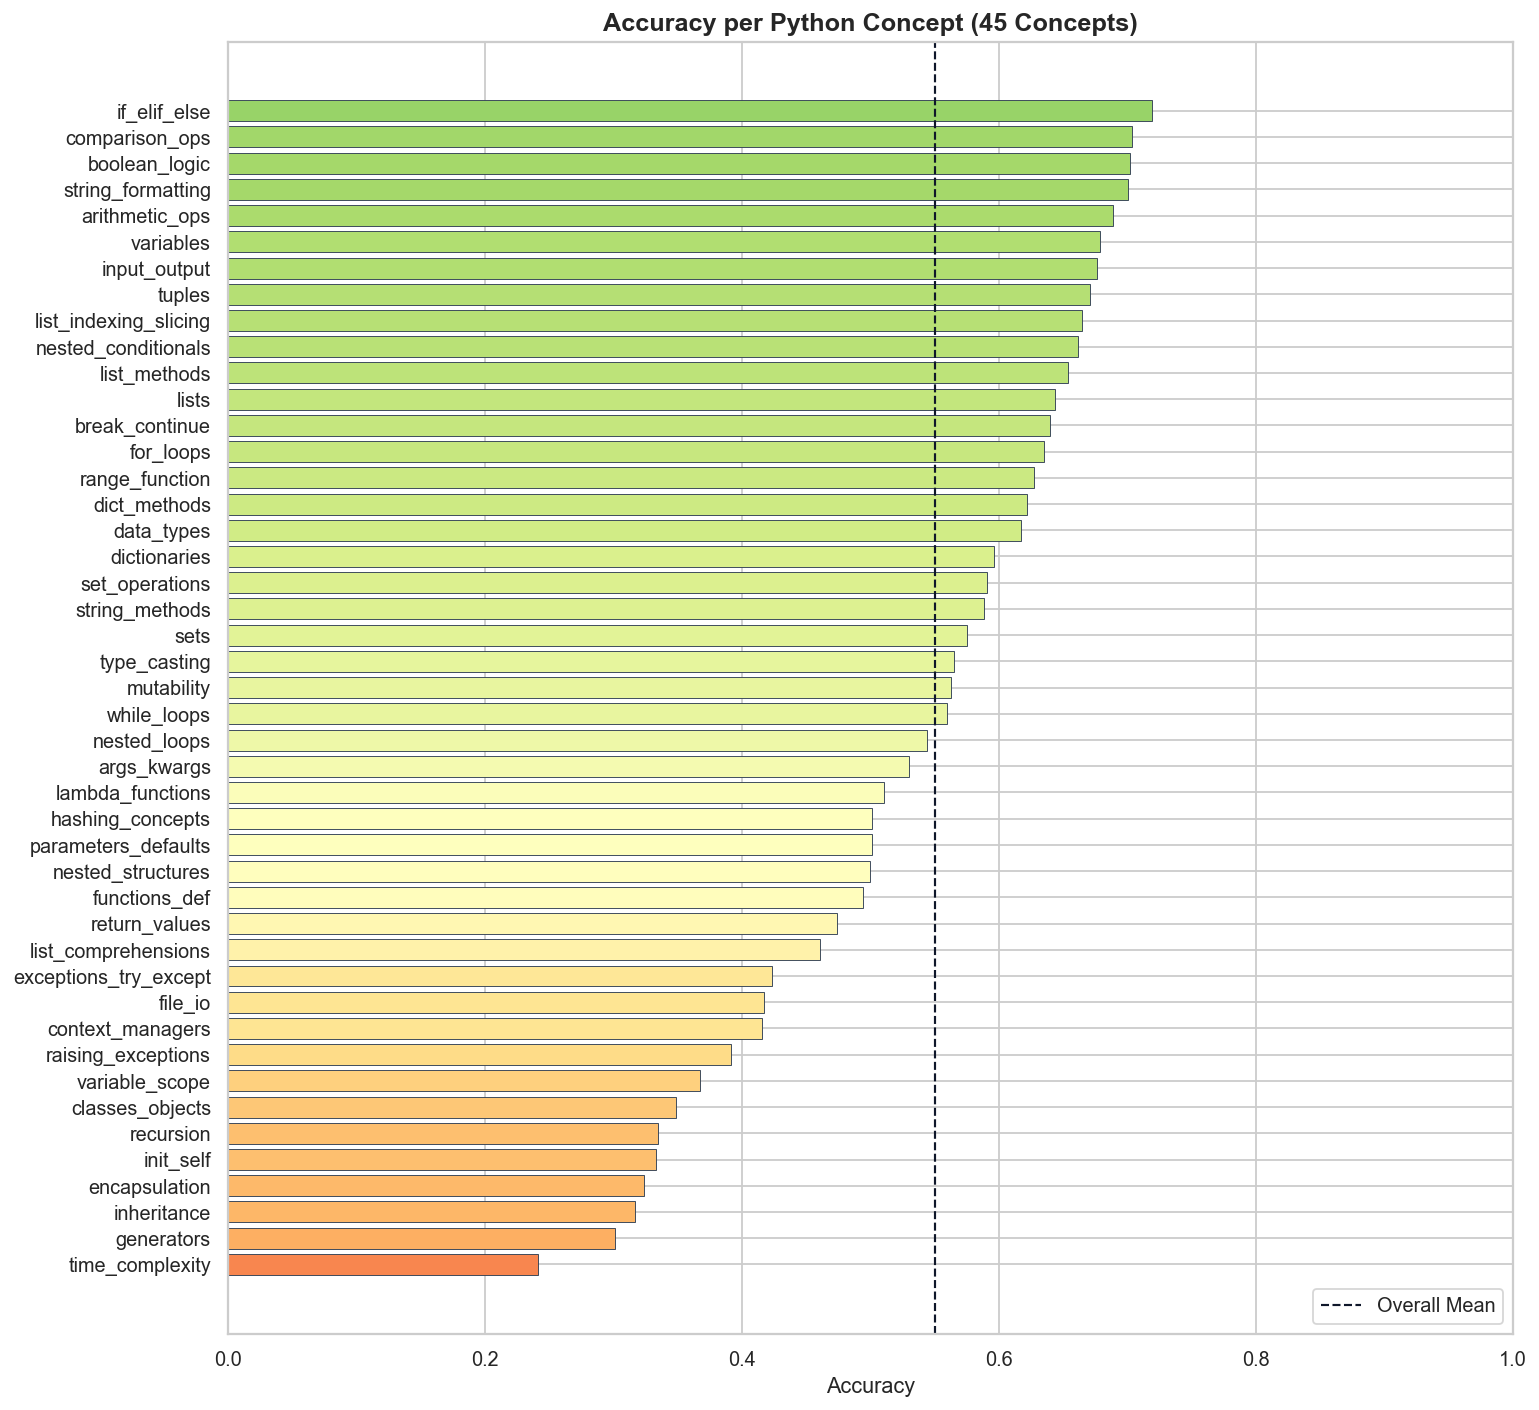

In [2]:
concept_acc = (
    interactions.groupby(['concept_id', 'week'], as_index=False)['correct']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'accuracy', 'count': 'attempts'})
    .sort_values('accuracy')
)

fig, ax = plt.subplots(figsize=(12, 11))
colors = plt.cm.RdYlGn(concept_acc['accuracy'])
ax.barh(concept_acc['concept_id'], concept_acc['accuracy'], color=colors, edgecolor='#334155', linewidth=0.5)
ax.axvline(interactions['correct'].mean(), color='#0f172a', linestyle='--', linewidth=1.2, label='Overall Mean')
ax.set_xlim(0, 1.0)
ax.set_xlabel('Accuracy')
ax.set_title('Accuracy per Python Concept (45 Concepts)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
fig.savefig(OUT_DIR / 'eda_accuracy_per_concept.png', dpi=150)
plt.show()

top_c = concept_acc.iloc[-1]
bot_c = concept_acc.iloc[0]
print(f'INSIGHT: Concept accuracy spans {bot_c["accuracy"]:.1%} ({bot_c["concept_id"]}) to '
      f'{top_c["accuracy"]:.1%} ({top_c["concept_id"]}), with steep drops on later/bottleneck topics.')


## 2. Learning Curves


INSIGHT: Accuracy rises by +1.8% from attempt 1 (52.7%) to attempt 3 (54.4%), confirming practice improves mastery across all ability tiers.


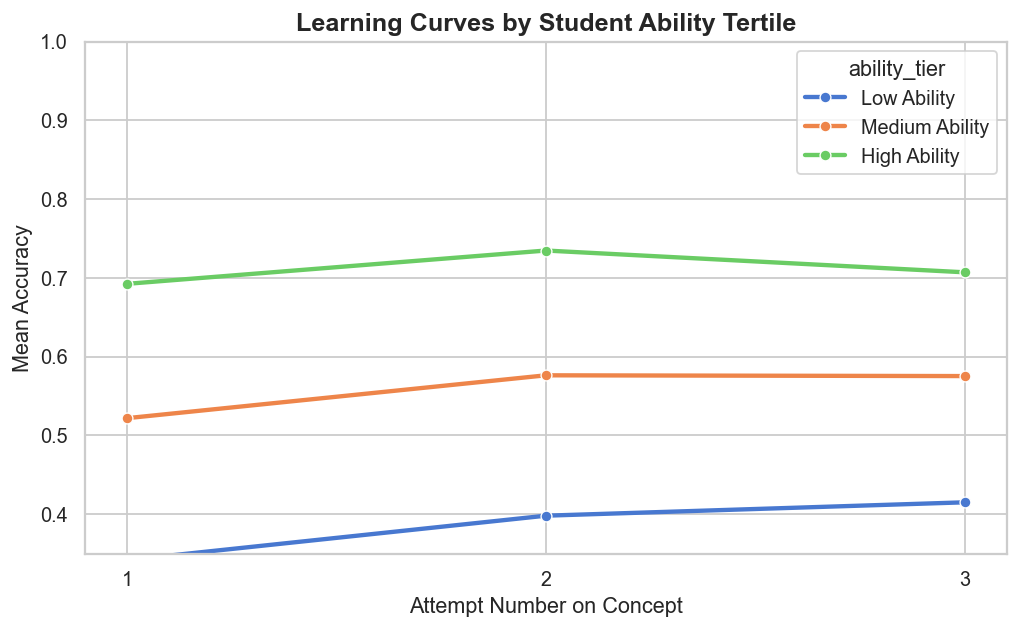

In [3]:
merged = interactions.merge(profiles[['student_id', 'ability']], on='student_id', how='left')
merged['ability_tier'] = pd.qcut(merged['ability'], q=3, labels=['Low Ability', 'Medium Ability', 'High Ability'])
lc = merged.groupby(['ability_tier', 'attempt_num'], observed=True)['correct'].mean().reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=lc, x='attempt_num', y='correct', hue='ability_tier', marker='o', linewidth=2.4, ax=ax)
ax.set_xticks([1, 2, 3])
ax.set_ylim(0.35, 1.0)
ax.set_xlabel('Attempt Number on Concept')
ax.set_ylabel('Mean Accuracy')
ax.set_title('Learning Curves by Student Ability Tertile', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_DIR / 'eda_learning_curves.png', dpi=150)
plt.show()

overall_lc = merged.groupby('attempt_num')['correct'].mean()
gain = overall_lc.iloc[-1] - overall_lc.iloc[0]
print(f'INSIGHT: Accuracy rises by {gain:+.1%} from attempt 1 ({overall_lc.iloc[0]:.1%}) to attempt 3 '
      f'({overall_lc.iloc[-1]:.1%}), confirming practice improves mastery across all ability tiers.')


## 3. Dropout Points (Pre-Week-4 Attrition)


INSIGHT: 40.4% of students drop out before Week 4, peaking at "variables" (33 dropouts) where unaddressed prerequisite gaps compound.


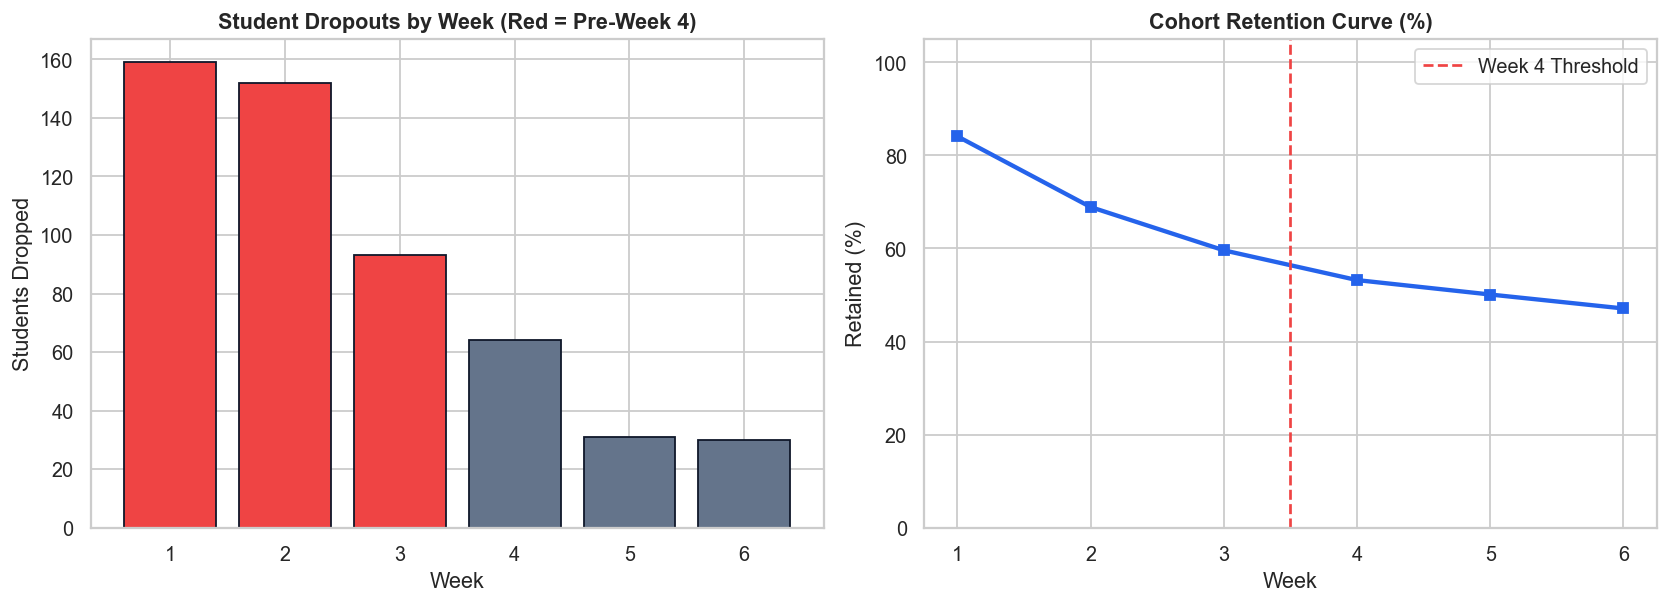

In [4]:
dropped = profiles[profiles['dropped_out'] == 1]
weekly_drop = dropped['dropout_week'].value_counts().sort_index().reindex(range(1, 7), fill_value=0)
cum_retained = 1.0 - (weekly_drop.cumsum() / len(profiles))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
bar_colors = ['#ef4444' if w < 4 else '#64748b' for w in weekly_drop.index]
axes[0].bar(weekly_drop.index, weekly_drop.values, color=bar_colors, edgecolor='#0f172a')
axes[0].set_title('Student Dropouts by Week (Red = Pre-Week 4)', fontweight='bold')
axes[0].set_xlabel('Week')
axes[0].set_ylabel('Students Dropped')

axes[1].plot(cum_retained.index, cum_retained.values * 100, marker='s', color='#2563eb', linewidth=2.4)
axes[1].axvline(3.5, color='#ef4444', linestyle='--', label='Week 4 Threshold')
axes[1].set_ylim(0, 105)
axes[1].set_title('Cohort Retention Curve (%)', fontweight='bold')
axes[1].set_xlabel('Week')
axes[1].set_ylabel('Retained (%)')
axes[1].legend()
plt.tight_layout()
fig.savefig(OUT_DIR / 'eda_dropout_points.png', dpi=150)
plt.show()

top_drop_concept = dropped['dropout_concept'].value_counts().index[0]
top_drop_cnt = dropped['dropout_concept'].value_counts().iloc[0]
print(f'INSIGHT: {pre_w4:.1%} of students drop out before Week 4, peaking at "{top_drop_concept}" ({top_drop_cnt} dropouts) '
      f'where unaddressed prerequisite gaps compound.')


## 4. Hardest Concepts


INSIGHT: "time_complexity" is the hardest concept (24.1% accuracy, 91s avg), marking it and other top-10 bottlenecks as prime targets for adaptive scaffolding.


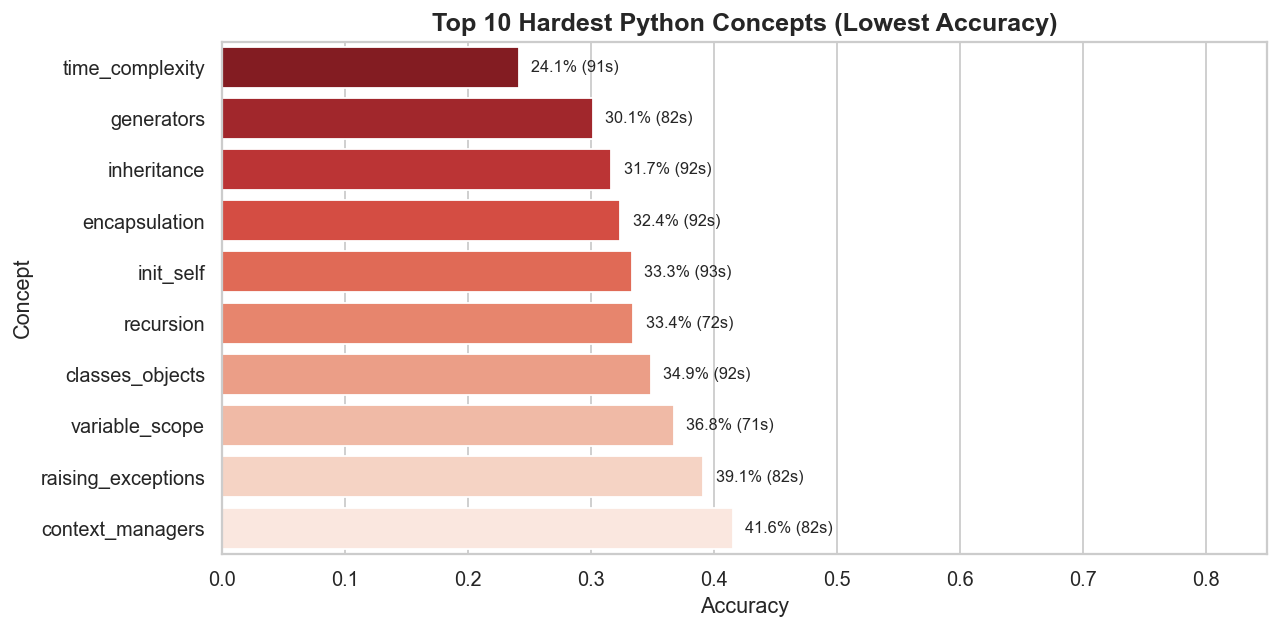

In [5]:
hardest = (
    interactions.groupby('concept_id', as_index=False)
    .agg(accuracy=('correct', 'mean'), avg_time_sec=('response_time_sec', 'mean'), attempts=('correct', 'count'))
    .sort_values('accuracy')
    .head(10)
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=hardest, x='accuracy', y='concept_id', hue='concept_id', palette='Reds_r', legend=False, ax=ax)
ax.set_xlim(0, 0.85)
ax.set_title('Top 10 Hardest Python Concepts (Lowest Accuracy)', fontsize=14, fontweight='bold')
ax.set_xlabel('Accuracy')
ax.set_ylabel('Concept')
for i, row in enumerate(hardest.itertuples()):
    ax.text(row.accuracy + 0.01, i, f'{row.accuracy:.1%} ({row.avg_time_sec:.0f}s)', va='center', fontsize=9)
plt.tight_layout()
fig.savefig(OUT_DIR / 'eda_hardest_concepts.png', dpi=150)
plt.show()

h1 = hardest.iloc[0]
print(f'INSIGHT: "{h1["concept_id"]}" is the hardest concept ({h1["accuracy"]:.1%} accuracy, {h1["avg_time_sec"]:.0f}s avg), '
      f'marking it and other top-10 bottlenecks as prime targets for adaptive scaffolding.')
